# RiskChecker: Risk Classification Analysis

This notebook explores the real CSV files shipped with RiskChecker and evaluates the same K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Decision Tree classifiers used by the application. The target is the three-class `Risk_Level` label (`Low`, `Medium`, `High`).

The supplied training and test files are kept separate. The test labels are used only for the final, held-out evaluation, not for fitting, cross-validation, or choosing the best model. Exact repeated feature vectors are grouped within CV and excluded from the test evaluation if already present in training. `Case_ID` is an identifier and is never used as a predictive feature. All reported tables and plots are calculated when the notebook runs.

## 1. Imports and configuration

The notebook locates the project root whether Jupyter is started from the repository root or this notebook's directory. It imports the feature definitions and model manager from the backend so the analysis follows the same input schema and preprocessing rules as the application.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_SEED = 42

working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [working_dir, *working_dir.parents]
     if (path / 'backend' / 'data').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate backend/data from the current directory.')
BACKEND_DIR = PROJECT_ROOT / 'backend'
sys.path.insert(0, str(BACKEND_DIR))

from config import DATA_DIR, NUMERIC_FEATURES, RISK_CATEGORIES, TARGET_CLASSES
from models.model_manager import ARTIFACT_PATH, ModelManager
from preprocessing.pipeline import PreprocessingPipeline

TRAIN_PATH = Path(DATA_DIR) / 'train_risk_dataset.csv'
TEST_PATH = Path(DATA_DIR) / 'test_risk_dataset.csv'
HISTORICAL_PATH = Path(DATA_DIR) / 'historical_risk_dataset.csv'
FEATURE_COLUMNS = ['Category', *NUMERIC_FEATURES.keys()]
TARGET = 'Risk_Level'
ID_COLUMN = 'Case_ID'
print(f'Project root: {PROJECT_ROOT}')
print(f'Random seed: {RANDOM_SEED}')

ModuleNotFoundError: No module named 'seaborn'

## 2. Load the supplied datasets

RiskChecker supplies separate labeled training and test CSV files. A historical combined CSV is also present for exploration, but the model manager uses the named train/test split when both files exist. The test file is not merged into training.

In [ ]:
for path in (TRAIN_PATH, TEST_PATH, HISTORICAL_PATH):
    if not path.is_file():
        raise FileNotFoundError(f'Required dataset file is missing: {path}')

train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)
historical = pd.read_csv(HISTORICAL_PATH)
dataset_sizes = pd.DataFrame([
    {'file': path.name, 'rows': len(frame), 'columns': len(frame.columns)}
    for path, frame in [
        (TRAIN_PATH, train_raw), (TEST_PATH, test_raw),
        (HISTORICAL_PATH, historical),
    ]
])
display(dataset_sizes)

,file,rows,columns
0,train_risk_dataset.csv,20000,11
1,test_risk_dataset.csv,20000,11
2,historical_risk_dataset.csv,40000,11


## 3. Initial inspection and schema validation

A schema check makes unexpected/missing columns or unlabeled records visible before analysis. Feature definitions below are read from the backend configuration rather than copied into the notebook. `Case_ID` is retained for integrity checks only.

In [ ]:
required_columns = {ID_COLUMN, *FEATURE_COLUMNS, TARGET}
for name, frame in [('train', train_raw), ('test', test_raw), ('historical', historical)]:
    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(f'{name} dataset is missing required columns: {sorted(missing_columns)}')
    if frame[TARGET].isna().any():
        raise ValueError(f'{name} dataset contains unlabeled target values.')
    invalid_targets = set(frame[TARGET].dropna().unique()) - set(TARGET_CLASSES)
    if invalid_targets:
        raise ValueError(f'{name} dataset contains unknown target labels: {sorted(invalid_targets)}')

if set(train_raw.columns) != set(test_raw.columns):
    raise ValueError('Training and test columns do not match.')

feature_descriptions = {
    ID_COLUMN: 'Record identifier; excluded from model features.',
    'Category': 'Risk domain/category.',
    **{name: details['description'] for name, details in NUMERIC_FEATURES.items()},
    TARGET: 'Observed three-level risk class to be predicted.',
}
schema = pd.DataFrame({
    'column': train_raw.columns,
    'dtype': train_raw.dtypes.astype(str).values,
    'description': [feature_descriptions.get(col, 'Additional supplied field.') for col in train_raw.columns],
    'model_feature': [col in FEATURE_COLUMNS for col in train_raw.columns],
})
display(schema)

,column,dtype,description,model_feature
0,Case_ID,object,Record identifier; excluded from model features.,False
1,Category,object,Risk domain/category.,True
2,Severity,float64,Potential magnitude of consequence,True
3,Likelihood,float64,Probability of occurrence,True
4,Exposure,float64,Scope of assets / operations affected,True
5,Frequency,float64,Recurrence rate of risk trigger,True
6,Duration,float64,Expected downtime / resolution time,True
7,Impact,float64,Collateral financial & operational impact,True
8,Historical_Occurrence,float64,Past incidents recorded (past 3 years),True
9,Control_Effectiveness,float64,Safeguards and mitigation strength,True


## 4. Data quality and split-integrity checks

Missing values and duplicate rows are measured for each supplied file. Duplicate records remain in the application training data for compatibility with its existing workflow; their frequency is reported because repeated rows can overweight particular examples. The identifiers are also checked for overlap between training and test.

In [ ]:
def quality_summary(name, frame):
    return {
        'dataset': name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'missing_cells': int(frame.isna().sum().sum()),
        'duplicate_rows': int(frame.duplicated().sum()),
        'duplicate_ids': int(frame[ID_COLUMN].duplicated().sum()),
        'unique_ids': int(frame[ID_COLUMN].nunique()),
    }

quality = pd.DataFrame([
    quality_summary('train', train_raw),
    quality_summary('test', test_raw),
    quality_summary('historical', historical),
])
display(quality)
id_overlap = set(train_raw[ID_COLUMN]) & set(test_raw[ID_COLUMN])
print(f'Train/test identifier overlap: {len(id_overlap):,}')
train_row_hashes = set(pd.util.hash_pandas_object(
    train_raw[FEATURE_COLUMNS + [TARGET]].drop_duplicates(), index=False))
test_row_hashes = set(pd.util.hash_pandas_object(
    test_raw[FEATURE_COLUMNS + [TARGET]].drop_duplicates(), index=False))
print(f'Train/test identical unique feature-and-target rows: {len(train_row_hashes & test_row_hashes):,}')
print('Note: duplicate identifiers or repeated rows limit the number of independent observations.')

,dataset,rows,columns,missing_cells,duplicate_rows,duplicate_ids,unique_ids
0,train,20000,11,0,4533,4533,15467
1,test,20000,11,0,5058,5058,14942
2,historical,40000,11,0,9591,9591,30409


Train/test identifier overlap: 0
Train/test identical unique feature-and-target rows: 2,861
Note: duplicate identifiers or repeated rows limit the number of independent observations.


## 5. Target distribution and class balance

The target is categorical, so this is a multi-class classification problem. The following counts and proportions are calculated directly from the supplied records; balanced labels do not by themselves establish that the classes reflect real-world risk prevalence.

,count,proportion
Risk_Level,,
Low,6668,0.3334
Medium,6666,0.3333
High,6666,0.3333


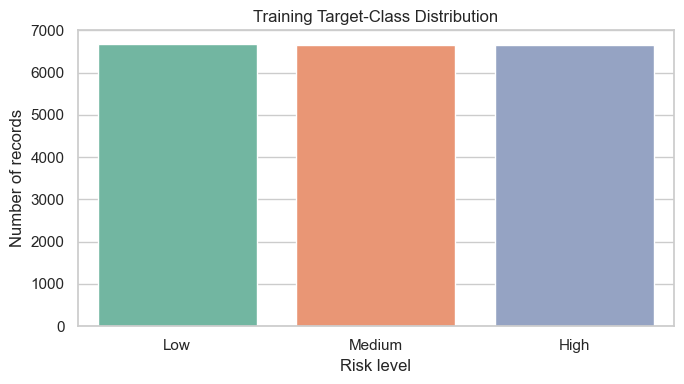

In [ ]:
target_counts = train_raw[TARGET].value_counts().reindex(TARGET_CLASSES, fill_value=0)
target_table = pd.DataFrame({'count': target_counts, 'proportion': target_counts / len(train_raw)})
display(target_table)
plt.figure(figsize=(7, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, hue=target_counts.index,
            palette='Set2', legend=False)
plt.title('Training Target-Class Distribution')
plt.xlabel('Risk level')
plt.ylabel('Number of records')
plt.tight_layout()
plt.show()

## 6. Numerical feature distributions and outliers

Histograms reveal the observed scale and concentration of each numerical input. The IQR table flags values outside 1.5 times the interquartile range; a flagged value is not automatically an error. The application caps numerical extremes using bounds learned from its training data.

,count,mean,std,min,25%,50%,75%,max
Severity,20000.0,5.714350,2.222742,1.0,3.5,5.5,7.5,10.0
Likelihood,20000.0,5.965190,2.166854,1.1,4.6,5.8,7.7,9.8
Exposure,20000.0,7.343885,2.028315,1.6,5.0,8.3,8.8,10.0
Frequency,20000.0,7.269910,1.828046,2.5,7.0,8.0,8.5,9.0
Duration,20000.0,5.169470,2.188021,3.1,3.5,3.9,8.1,8.9
Impact,20000.0,5.987355,2.384255,1.5,3.4,6.0,9.2,9.5
Historical_Occurrence,20000.0,9.536250,1.221417,1.0,10.0,10.0,10.0,10.0
Control_Effectiveness,20000.0,5.099270,2.202322,2.1,3.1,5.3,6.5,9.9


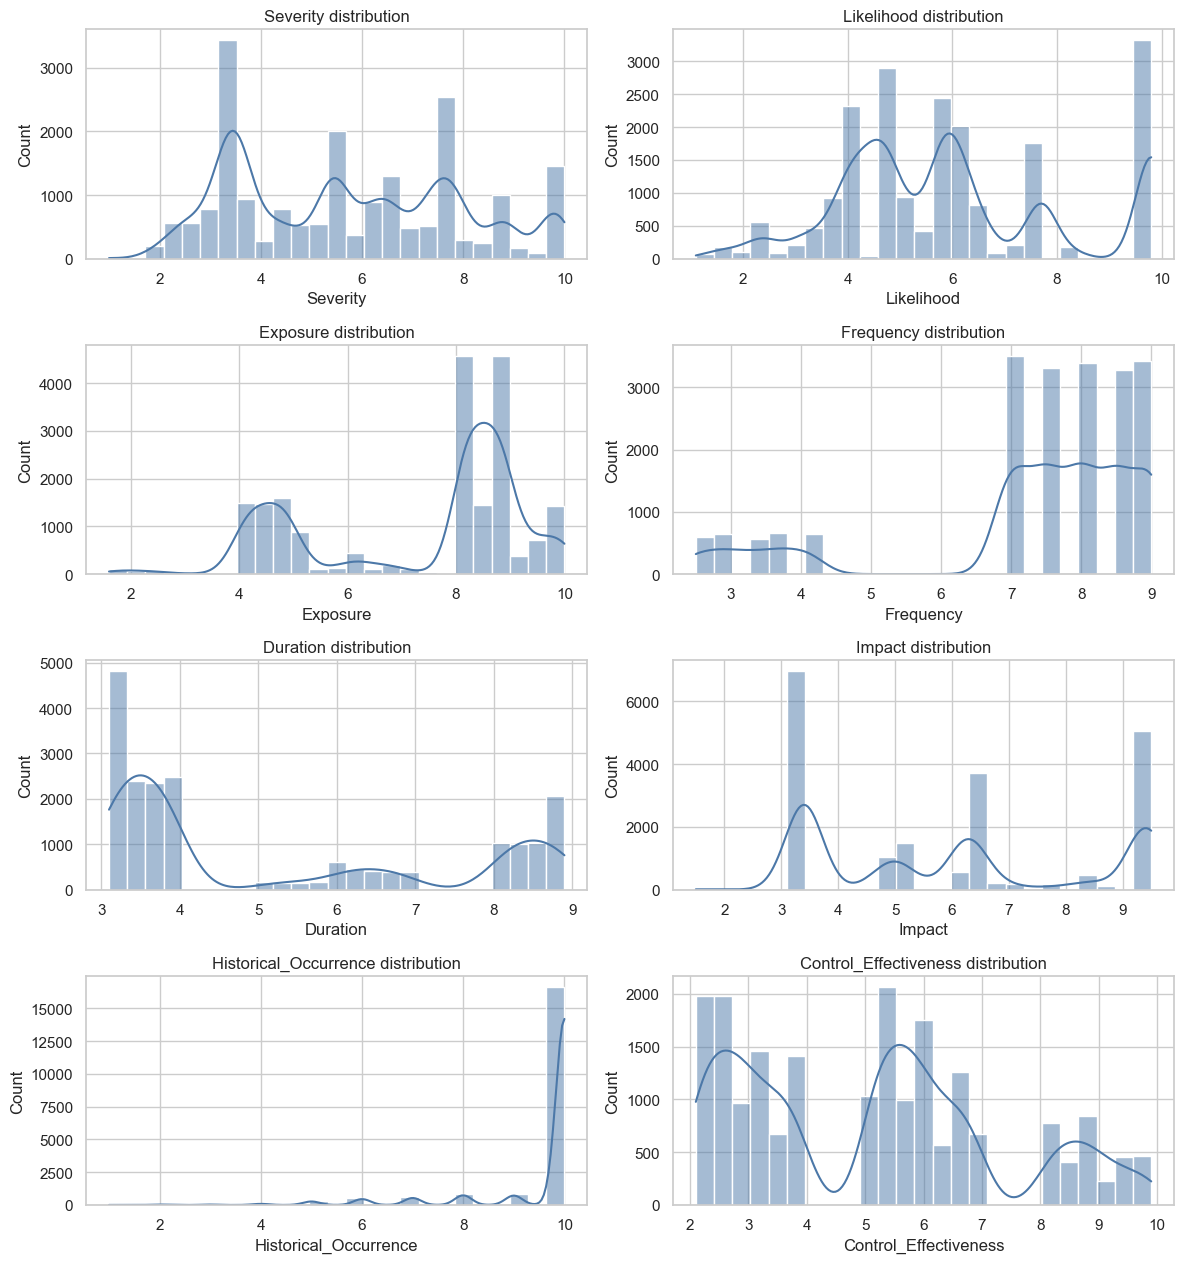

,lower_fence,upper_fence,outlier_count,outlier_rate
feature,,,,
Severity,-2.50,13.50,0,0.0000
Likelihood,-0.05,12.35,0,0.0000
Exposure,-0.70,14.50,0,0.0000
Frequency,4.75,10.75,3093,0.1546
Duration,-3.40,15.00,0,0.0000
Impact,-5.30,17.90,0,0.0000
Historical_Occurrence,10.00,10.00,3341,0.1670
Control_Effectiveness,-2.00,11.60,0,0.0000


In [ ]:
numeric_columns = list(NUMERIC_FEATURES.keys())
display(train_raw[numeric_columns].describe().T)
ncols = 2
nrows = int(np.ceil(len(numeric_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows))
for column, axis in zip(numeric_columns, np.asarray(axes).ravel()):
    sns.histplot(data=train_raw, x=column, bins=25, kde=True, ax=axis, color='#4C78A8')
    axis.set_title(f'{column} distribution')
for axis in np.asarray(axes).ravel()[len(numeric_columns):]:
    axis.remove()
plt.tight_layout()
plt.show()

outlier_rows = []
for column in numeric_columns:
    q1, q3 = train_raw[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((train_raw[column] < lower) | (train_raw[column] > upper)).sum())
    outlier_rows.append({'feature': column, 'lower_fence': lower, 'upper_fence': upper,
                         'outlier_count': count, 'outlier_rate': count / len(train_raw)})
outlier_table = pd.DataFrame(outlier_rows).set_index('feature')
display(outlier_table.round(4))

## 7. Categorical feature distribution

`Category` identifies the risk domain. This plot shows the category representation in the training split; categories are one-hot encoded by the backend preprocessor, and unexpected values are handled as unknown categories rather than converted into an identifier.

,count
Category,
Business,4689
Infrastructure,3890
Project,3218
Operational,1931
Safety,1813
Environmental,1753
Financial,1578
Cybersecurity,1128


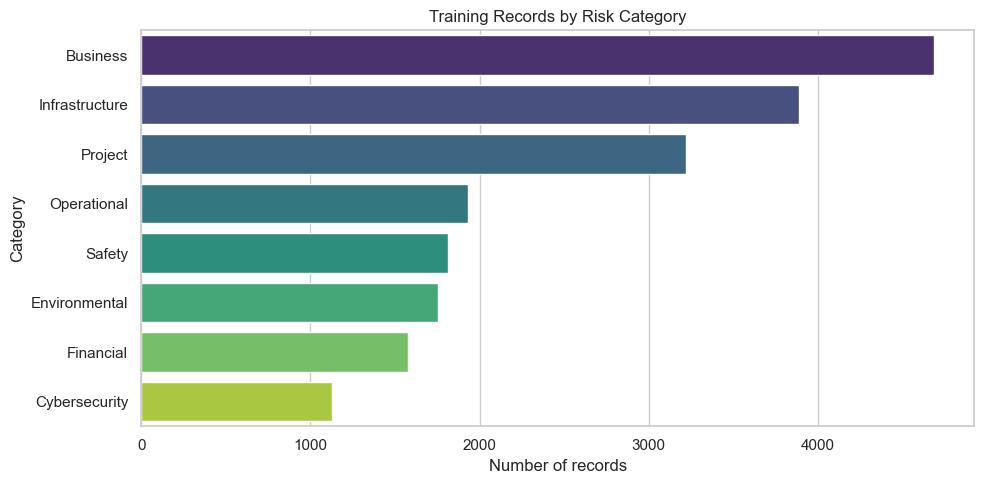

Categories not listed in backend configuration: []


In [ ]:
category_counts = train_raw['Category'].value_counts().sort_values(ascending=False)
display(category_counts.rename('count').to_frame())
plt.figure(figsize=(10, 5))
sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index,
            palette='viridis', legend=False)
plt.title('Training Records by Risk Category')
plt.xlabel('Number of records')
plt.ylabel('Category')
plt.tight_layout()
plt.show()
unknown_categories = set(train_raw['Category'].dropna().unique()) - set(RISK_CATEGORIES)
print(f'Categories not listed in backend configuration: {sorted(unknown_categories)}')

## 8. Correlations and feature relationships with the target

The heatmap is limited to numerical inputs. It describes pairwise linear association, not causation. Boxplots and grouped averages compare measured input distributions across the target classes and are descriptive rather than causal explanations.

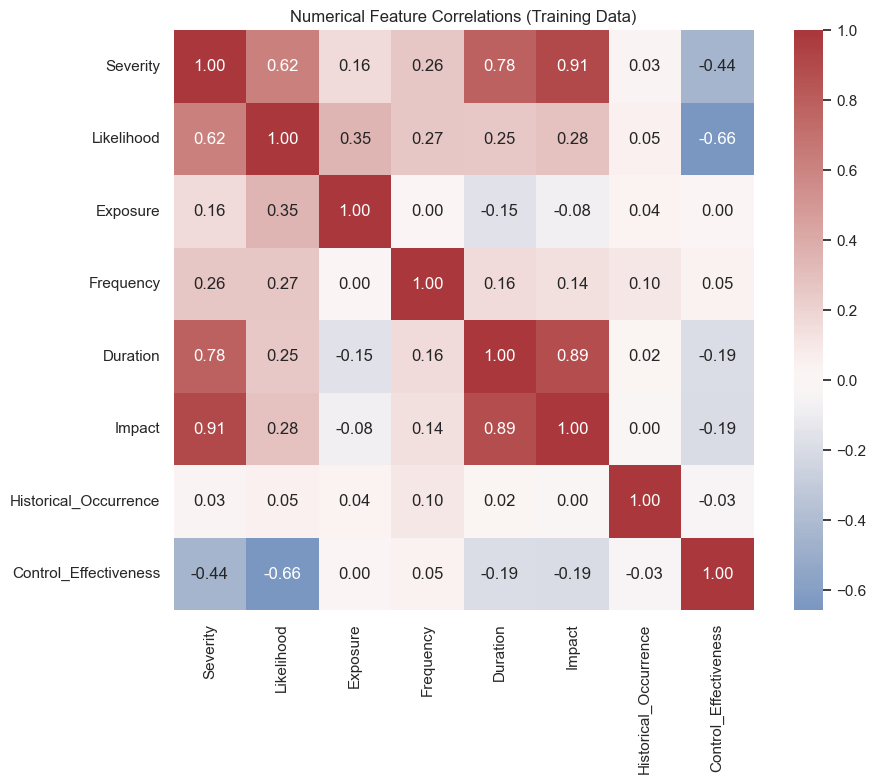

,Severity,Likelihood,Exposure,Frequency,Duration,Impact,Historical_Occurrence,Control_Effectiveness
Risk_Level,,,,,,,,
Low,3.219,4.514,6.985,6.573,3.503,3.580,9.446,6.050
Medium,5.586,5.898,7.521,7.548,4.509,5.722,9.624,5.336
High,8.340,7.484,7.526,7.688,7.497,8.661,9.539,3.912


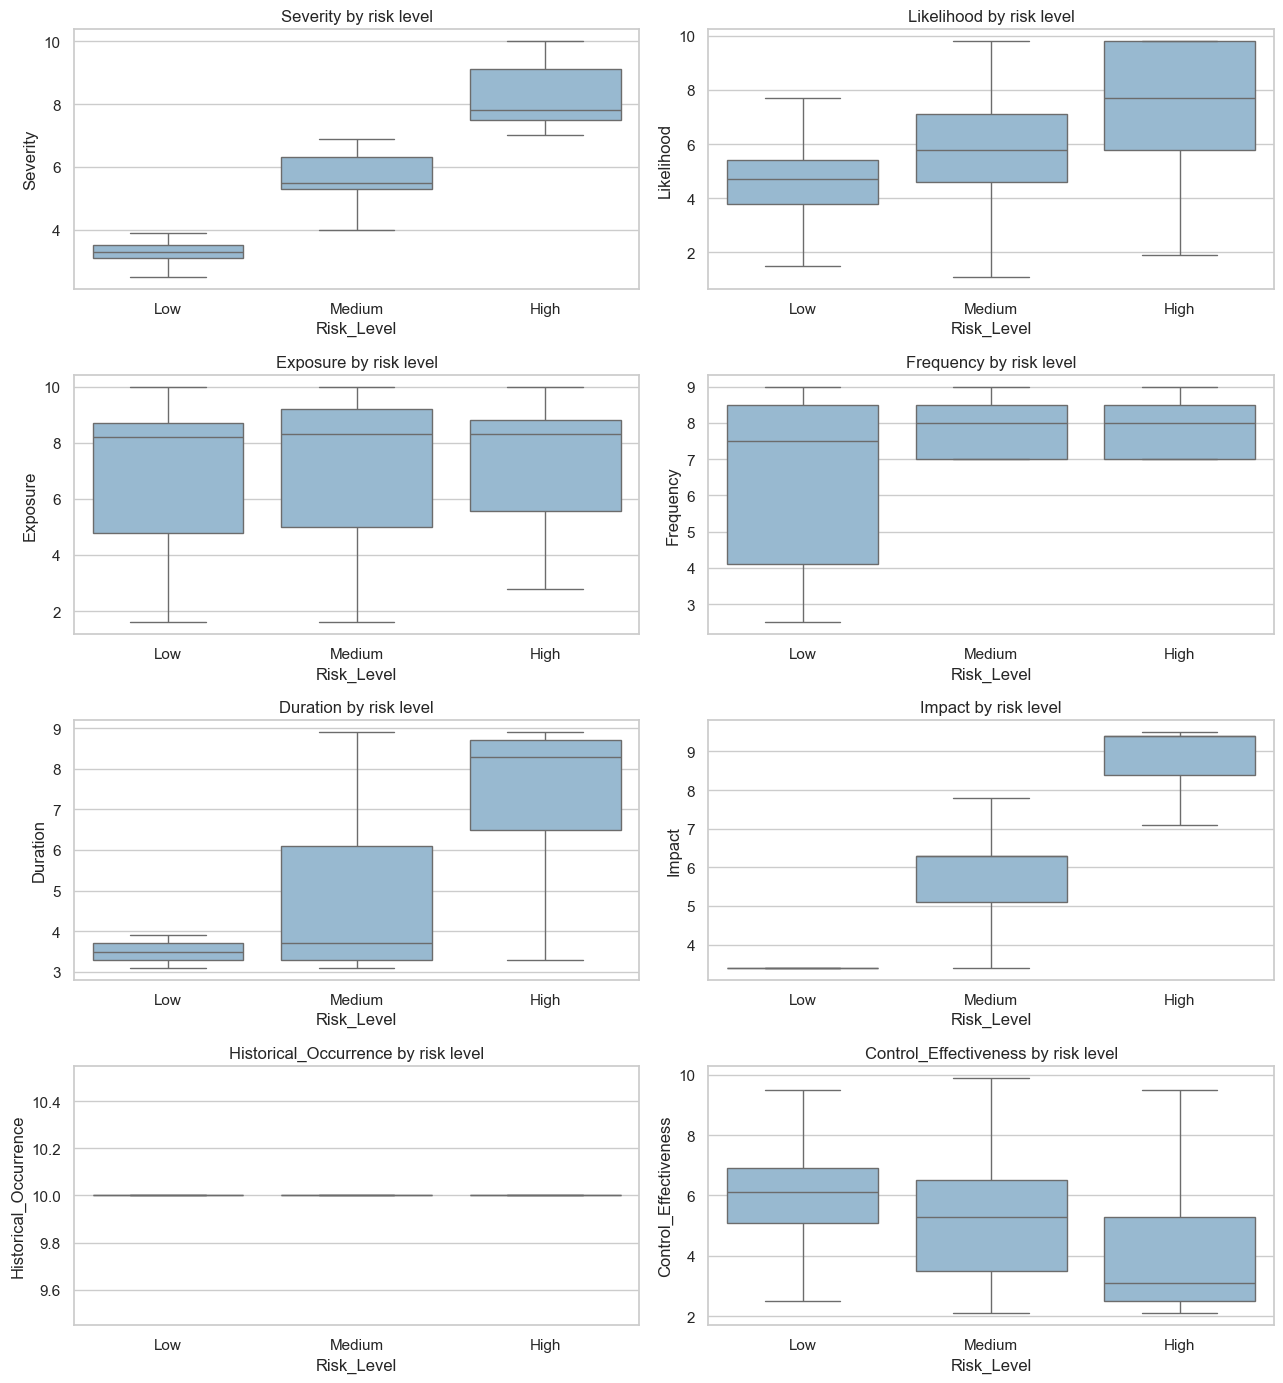

In [ ]:
correlations = train_raw[numeric_columns].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(correlations, cmap='vlag', center=0, annot=True, fmt='.2f', square=True)
plt.title('Numerical Feature Correlations (Training Data)')
plt.tight_layout()
plt.show()

target_means = train_raw.groupby(TARGET, observed=False)[numeric_columns].mean().reindex(TARGET_CLASSES)
display(target_means.round(3))
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for column, axis in zip(numeric_columns, axes.ravel()):
    sns.boxplot(data=train_raw, x=TARGET, y=column, order=TARGET_CLASSES, ax=axis,
                showfliers=False, color='#8FBBD9')
    axis.set_title(f'{column} by risk level')
plt.tight_layout()
plt.show()

## 9. Preprocessing and train/validation/test design

The backend uses median imputation for numeric inputs, most-frequent imputation for the category, one-hot encoding, standard scaling, and IQR-based capping. Each cross-validation fold fits its own preprocessing pipeline using only that fold's training portion, and duplicate feature vectors remain in the same fold. The final pipeline is fitted on the full supplied training split. Test labels remain separate and are used only for final evaluation; duplicate feature vectors already seen in training are excluded from the primary test metrics.

In [ ]:
split_check = pd.DataFrame([
    {'split': 'training', 'rows': len(train_raw), 'labeled': int(train_raw[TARGET].notna().sum()),
     'columns_match': set(train_raw.columns) == set(test_raw.columns)},
    {'split': 'test', 'rows': len(test_raw), 'labeled': int(test_raw[TARGET].notna().sum()),
     'columns_match': set(train_raw.columns) == set(test_raw.columns)},
])
display(split_check)
print('Model features:', FEATURE_COLUMNS)
print('Excluded identifier:', ID_COLUMN)
print('Test labels are available and are reserved for final model evaluation.')

,split,rows,labeled,columns_match
0,training,20000,20000,True
1,test,20000,20000,True


Model features: ['Category', 'Severity', 'Likelihood', 'Exposure', 'Frequency', 'Duration', 'Impact', 'Historical_Occurrence', 'Control_Effectiveness']
Excluded identifier: Case_ID
Test labels are available and are reserved for final model evaluation.


## 10. Models, fitting, and cross-validation

The application supports three appropriate classifiers: KNN compares cases in the scaled feature space, SVM learns nonlinear decision boundaries, and a bounded-depth Decision Tree provides readable rules. The manager applies one consistent preprocessing configuration and a reproducible stratified five-fold validation procedure. Macro F1 is used for selection because it gives each risk level equal weight; recall for `High` remains an important safety-oriented companion metric. Hyperparameters remain at the application's documented defaults so the notebook comparison matches production inference. A search over parameters would optimize reproduction of the known label rule rather than establish real-world validity; no tuning result is claimed.

In [ ]:
model_notes = pd.DataFrame([
    {'model': 'K-Nearest Neighbors', 'reason': 'Local similarity baseline; feature scaling is important.'},
    {'model': 'Support Vector Machine (RBF)', 'reason': 'Can represent nonlinear class boundaries on scaled features.'},
    {'model': 'Decision Tree', 'reason': 'Captures nonlinear splits and supports rule-path explanations.'},
])
display(model_notes)
manager = ModelManager()
summary = manager.initialize(cv_folds=5, force_retrain=True)
print(f"Training rows: {len(manager.train_df):,}; supplied test rows: {len(manager.test_df):,}; "
      f"unique unseen test feature vectors: {len(manager.test_eval_df):,}")
print(f"Selected model by five-fold validation macro F1: {summary['best_model']['display_name']}")
print(f"Fitted backend model artifact: {ARTIFACT_PATH}")

,model,reason
0,K-Nearest Neighbors,Local similarity baseline; feature scaling is ...
1,Support Vector Machine (RBF),Can represent nonlinear class boundaries on sc...
2,Decision Tree,Captures nonlinear splits and supports rule-pa...


Models successfully trained & cross-validated. Best model: DECISION_TREE (CV F1-Macro: 1.0)
Training rows: 20,000; supplied test rows: 20,000; unique unseen test feature vectors: 6,593
Selected model by five-fold validation macro F1: Decision Tree (Gini, Depth=5)
Fitted backend model artifact: C:\Users\Sathw\Downloads\RiskChecker-main\RiskChecker-main\backend\models_cache\risk_models_v1.joblib


## 11. Model comparison and metric interpretation

Accuracy is the fraction of correct predictions. Macro precision measures correctness among predictions for each class and averages classes equally; macro recall measures recovered examples from each class; macro F1 balances those two. One-vs-rest macro ROC-AUC measures ranking separation for each class. Cross-validation mean and standard deviation summarize training-split validation performance and fold-to-fold variability. Test metrics are held-out results, not used for selecting the model.

In [ ]:
comparison_rows = []
for key, evaluation in manager.evaluations.items():
    cv = manager.cross_validations[key]
    comparison_rows.append({
        'model_key': key,
        'model': evaluation['display_name'],
        'test_accuracy': evaluation['accuracy'],
        'test_macro_precision': evaluation['precision_macro'],
        'test_macro_recall': evaluation['recall_macro'],
        'test_macro_f1': evaluation['f1_macro'],
        'test_roc_auc_ovr_macro': evaluation.get('roc_auc_ovr_macro', np.nan),
        'cv_macro_f1_mean': cv['mean_f1_macro'],
        'cv_macro_f1_std': cv['std_f1_macro'],
        'cv_macro_precision_mean': cv['mean_precision'],
        'cv_macro_precision_std': cv['std_precision'],
        'cv_macro_recall_mean': cv['mean_recall'],
        'cv_macro_recall_std': cv['std_recall'],
        'cv_roc_auc_ovr_macro_mean': cv.get('mean_roc_auc_ovr_macro', np.nan),
        'cv_roc_auc_ovr_macro_std': cv.get('std_roc_auc_ovr_macro', np.nan),
    })
comparison = pd.DataFrame(comparison_rows).sort_values('cv_macro_f1_mean', ascending=False)
display(comparison.round(4))
best_key = manager.best_model_name
best_evaluation = manager.evaluations[best_key]
best_cv = manager.cross_validations[best_key]
high_class = best_evaluation['class_metrics'].get('High', {})
print(f"Selected: {best_evaluation['display_name']} (CV macro F1 "
      f"{best_cv['mean_f1_macro']:.4f} +/- {best_cv['std_f1_macro']:.4f})")
print(f"Held-out High-risk recall: {high_class.get('recall', float('nan')):.4f}")

,model_key,model,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc_ovr_macro,cv_macro_f1_mean,cv_macro_f1_std,cv_macro_precision_mean,cv_macro_precision_std,cv_macro_recall_mean,cv_macro_recall_std,cv_roc_auc_ovr_macro_mean,cv_roc_auc_ovr_macro_std
2,decision_tree,"Decision Tree (Gini, Depth=5)",1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.000,0.0000
1,svm,"SVM (RBF Kernel, C=1.0)",0.9927,0.9907,0.9939,0.9923,0.9999,0.9965,0.0009,0.9966,0.0009,0.9965,0.0009,1.000,0.0000
0,knn,"KNN (k=5, euclidean, distance)",0.9519,0.9422,0.9607,0.9507,0.9872,0.9814,0.0014,0.9814,0.0015,0.9814,0.0014,0.995,0.0007


Selected: Decision Tree (Gini, Depth=5) (CV macro F1 1.0000 +/- 0.0000)
Held-out High-risk recall: 1.0000


## 12. Model-comparison visualization

These bars compare held-out test scores with cross-validation macro F1. They are generated from the actual run. The CV score is the selection basis; test scores are reported separately as final holdout results.

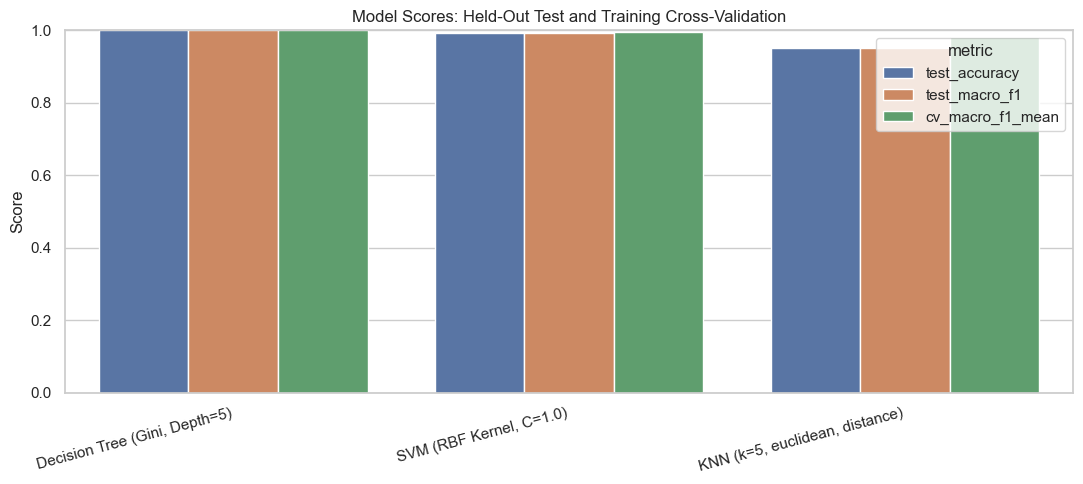

In [ ]:
plot_data = comparison.melt(
    id_vars='model',
    value_vars=['test_accuracy', 'test_macro_f1', 'cv_macro_f1_mean'],
    var_name='metric', value_name='score',
)
plt.figure(figsize=(11, 5))
sns.barplot(data=plot_data, x='model', y='score', hue='metric')
plt.ylim(0, 1)
plt.ylabel('Score')
plt.xlabel('')
plt.title('Model Scores: Held-Out Test and Training Cross-Validation')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

## 13. Out-of-fold validation predictions

Every training row is predicted by a model that did not fit on that row. Preprocessing is refit inside each fold. These out-of-fold predictions make validation errors inspectable without using the held-out test set.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold

raw_train_features = manager.train_df[FEATURE_COLUMNS]
oof_predictions = np.empty(len(manager.y_train), dtype=object)
validation_groups = pd.util.hash_pandas_object(raw_train_features, index=False).to_numpy()
validation_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
for fit_indices, validation_indices in validation_cv.split(
    raw_train_features, manager.y_train, groups=validation_groups
):
    fold_pipeline = PreprocessingPipeline()
    fold_pipeline.fit(raw_train_features.iloc[fit_indices])
    fold_classifier = clone(manager.models[best_key].model)
    fold_classifier.fit(
        fold_pipeline.transform(raw_train_features.iloc[fit_indices]),
        manager.y_train[fit_indices],
    )
    oof_predictions[validation_indices] = fold_classifier.predict(
        fold_pipeline.transform(raw_train_features.iloc[validation_indices])
    )

print(f'Out-of-fold accuracy: {accuracy_score(manager.y_train, oof_predictions):.4f}')
print(f'Out-of-fold macro F1: {f1_score(manager.y_train, oof_predictions, average="macro"):.4f}')
validation_preview = manager.train_df[[ID_COLUMN, TARGET]].head(12).copy()
validation_preview['oof_prediction'] = oof_predictions[:len(validation_preview)]
validation_preview['correct'] = validation_preview[TARGET] == validation_preview['oof_prediction']
display(validation_preview)

Out-of-fold accuracy: 1.0000
Out-of-fold macro F1: 1.0000


,Case_ID,Risk_Level,oof_prediction,correct
0,CVE-2023-31413,Low,Low,True
1,CVE-2023-43608,High,High,True
2,CVE-2023-26513,High,High,True
3,CVE-2023-25546,Low,Low,True
4,CVE-2022-31503,High,High,True
5,CVE-2023-1188,Low,Low,True
6,CVE-2022-30682,Medium,Medium,True
7,CVE-2023-41302,High,High,True
8,CVE-2023-33183,Low,Low,True
9,CVE-2022-22305,Medium,Medium,True


## 14. Confusion matrix and per-class diagnostics

A confusion matrix shows which true classes were predicted as each class. In a risk-support tool, misses in the `High` row deserve particular attention. The per-class table gives precision, recall, F1, and support for the selected model.

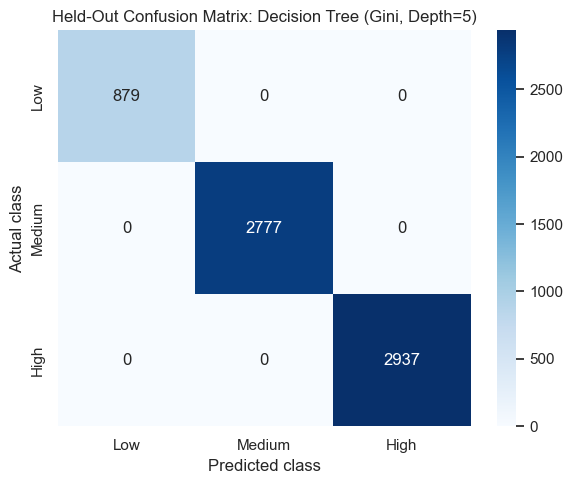

,precision,recall,f1,support
Low,1.0,1.0,1.0,879.0
Medium,1.0,1.0,1.0,2777.0
High,1.0,1.0,1.0,2937.0


In [ ]:
labels = best_evaluation['classes']
confusion = np.asarray(best_evaluation['confusion_matrix'])
plt.figure(figsize=(6, 5))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title(f"Held-Out Confusion Matrix: {best_evaluation['display_name']}")
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.tight_layout()
plt.show()
display(pd.DataFrame(best_evaluation['class_metrics']).T)

## 15. ROC and precision-recall curves

For a safety-oriented view, `High` is treated as positive and the other two classes as negative. The curves use the selected model's predicted probabilities on the held-out test rows. They are ranking diagnostics and do not define an operational decision threshold.

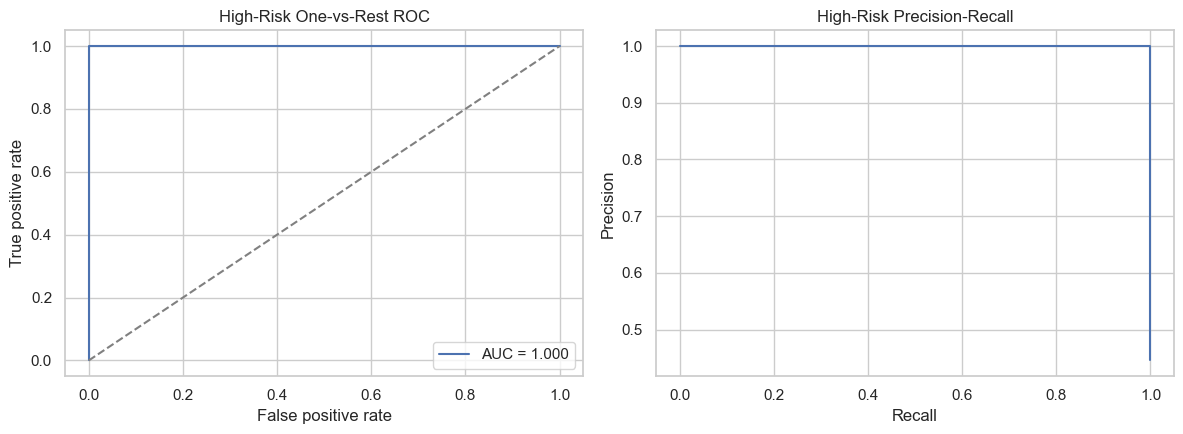

In [ ]:
from sklearn.metrics import auc, precision_recall_curve, roc_curve

best_model = manager.models[best_key]
test_probabilities = best_model.predict_proba(manager.X_test)
class_index = list(best_model.classes_).index('High')
high_scores = test_probabilities[:, class_index]
high_truth = (manager.y_test == 'High').astype(int)
fpr, tpr, _ = roc_curve(high_truth, high_scores)
precision, recall, _ = precision_recall_curve(high_truth, high_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[0].set(title='High-Risk One-vs-Rest ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend()
axes[1].plot(recall, precision)
axes[1].set(title='High-Risk Precision-Recall', xlabel='Recall', ylabel='Precision')
plt.tight_layout()
plt.show()

## 16. Interpretable feature importance

The application's Decision Tree exposes impurity-based feature importance. This indicates how much the fitted tree used each encoded input to reduce impurity; it is not proof that a feature causes risk. The chart is shown even when another classifier wins, as a supplementary explanation rather than a substitute for that model.

,feature,importance,importance_pct
0,Severity,1.0,100.0
1,Category_Infrastructure,0.0,0.0
2,Category_Safety,0.0,0.0
3,Category_Project,0.0,0.0
4,Category_Environmental,0.0,0.0
5,Category_Cybersecurity,0.0,0.0
6,Category_Operational,0.0,0.0
7,Category_Business,0.0,0.0
8,Category_Financial,0.0,0.0
9,Control_Effectiveness,0.0,0.0


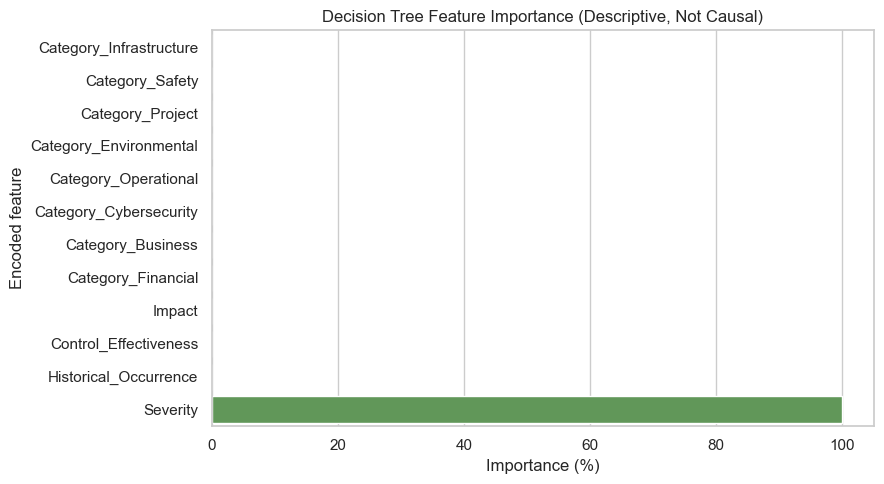

In [ ]:
tree_importances = pd.DataFrame(manager.models['decision_tree'].get_feature_importances())
if not tree_importances.empty:
    display(tree_importances.head(12))
    top_importances = tree_importances.head(12).sort_values('importance')
    plt.figure(figsize=(9, 5))
    sns.barplot(data=top_importances, x='importance_pct', y='feature', color='#59A14F')
    plt.title('Decision Tree Feature Importance (Descriptive, Not Causal)')
    plt.xlabel('Importance (%)')
    plt.ylabel('Encoded feature')
    plt.tight_layout()
    plt.show()

## 17. Example held-out predictions

The displayed examples are predictions for rows from the supplied test file and are not used to update the model. Only a small preview is shown; all test predictions are evaluated in the preceding tables.

In [ ]:
test_predictions = best_model.predict(manager.X_test)
prediction_preview = manager.test_eval_df[[ID_COLUMN, TARGET]].head(12).copy()
prediction_preview['predicted_Risk_Level'] = test_predictions[:len(prediction_preview)]
prediction_preview['correct'] = prediction_preview[TARGET] == prediction_preview['predicted_Risk_Level']
display(prediction_preview)

,Case_ID,Risk_Level,predicted_Risk_Level,correct
0,CVE-2024-7080,Medium,Medium,True
3,CVE-2024-48872,Medium,Medium,True
5,CVE-2024-45861,High,High,True
7,CVE-2024-3858,High,High,True
10,CVE-2024-11971,Low,Low,True
14,CVE-2024-42155,Low,Low,True
15,CVE-2024-4584,Medium,Medium,True
18,CVE-2024-32429,Medium,Medium,True
19,CVE-2024-10554,Low,Low,True
20,CVE-2024-27135,High,High,True


## 18. Persisted model, conclusions, and limitations

The manager saves the fitted preprocessing pipeline, all model wrappers, evaluation results, and the data needed by the current application's explanations and nearest-case retrieval in a versioned local artifact. The backend reads only this fixed application-managed artifact, checks its version and dataset/configuration fingerprint, and retrains if it does not match. Never load user-provided pickle/joblib files.

Limitations: the CSVs contain repeated rows and repeated identifiers, and their provenance/collection period is not recorded alongside the data. The repository's NVD builder maps the CVSS base severity/score to `Risk_Level` and also uses the same base score as `Severity`; the target is therefore directly encoded in a model input. Perfect scores should be interpreted as reproducing that label rule, not evidence of independent real-world prediction. Several other risk dimensions are derived/standardized values rather than independent observed outcomes. Train/test feature overlap is excluded from the primary test metrics, but remaining scores are still tied to the target construction. Treat predictions as decision support, inspect high-risk recall and false positives, and obtain independently labeled outcomes before deployment.

In [ ]:
report_path = Path(ARTIFACT_PATH).with_name('experiment_results.json')
with report_path.open('w', encoding='utf-8') as report_file:
    json.dump(summary, report_file, indent=2)

print('Conclusion')
print(f"- Selected model: {best_evaluation['display_name']} by five-fold CV macro F1.")
print(f"- CV macro F1: {best_cv['mean_f1_macro']:.4f} +/- {best_cv['std_f1_macro']:.4f}.")
print(f"- Held-out test macro F1: {best_evaluation['f1_macro']:.4f}.")
print(f"- Held-out unseen-feature cases: {len(manager.test_eval_df):,}.")
print(f"- Held-out High-risk recall: {high_class.get('recall', float('nan')):.4f}.")
print(f"- Versioned model artifact: {ARTIFACT_PATH}")
print(f"- Reproducible experiment summary: {report_path}")

Conclusion
- Selected model: Decision Tree (Gini, Depth=5) by five-fold CV macro F1.
- CV macro F1: 1.0000 +/- 0.0000.
- Held-out test macro F1: 1.0000.
- Held-out unseen-feature cases: 6,593.
- Held-out High-risk recall: 1.0000.
- Versioned model artifact: C:\Users\Sathw\Downloads\RiskChecker-main\RiskChecker-main\backend\models_cache\risk_models_v1.joblib
- Reproducible experiment summary: C:\Users\Sathw\Downloads\RiskChecker-main\RiskChecker-main\backend\models_cache\experiment_results.json
